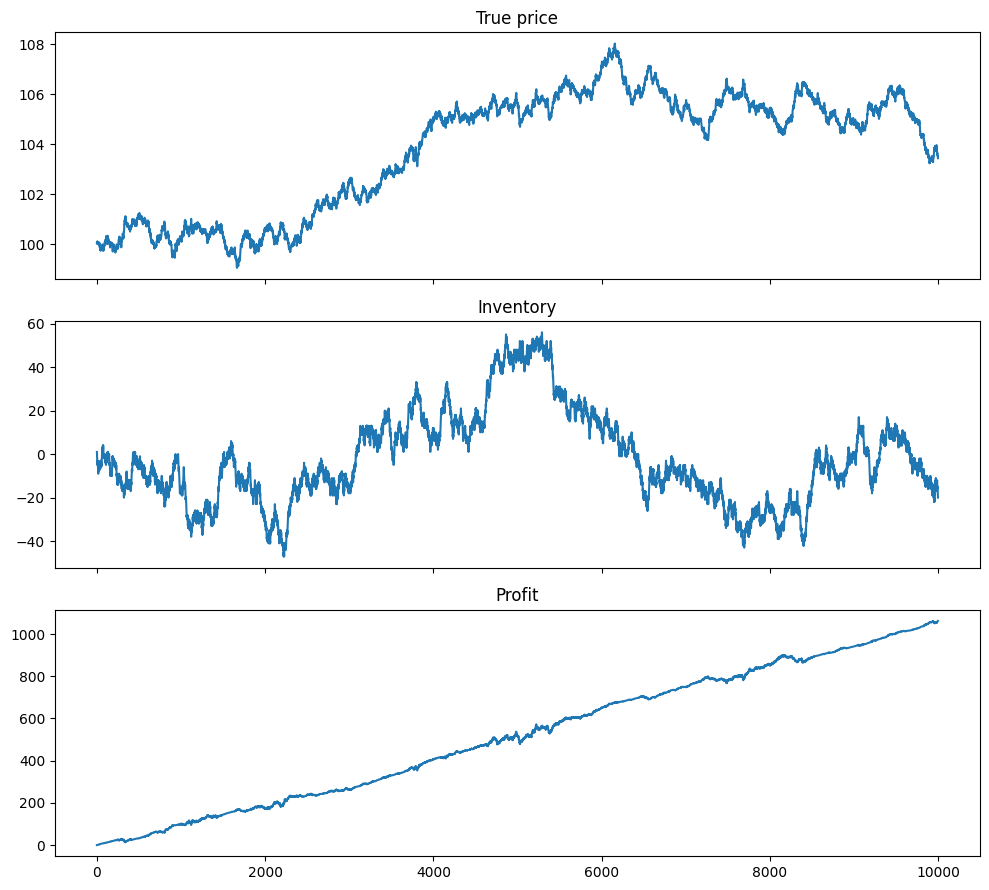

Final profit: 1062.0
Final inventory: -20


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

N_STEPS = 10000        # how long the simulation runs
SPREAD = 0.20          # total gap between bid and ask
P_BUYER = 0.50         # chance a buyer arrives each step
P_SELLER = 0.50        # chance a seller arrives each step
P_INFORMED = 0.15      # share of traders who know the next move
VOLATILITY = 0.05      # size of the random price moves
INVENTORY_LEAN = 0.002 # how hard we shift quotes to reduce inventory

true_price = 100.0
cash = 0.0
inventory = 0
records = []

for t in range(N_STEPS):

    move = np.random.normal(0, VOLATILITY)
    next_price = true_price + move

    estimate = true_price + np.random.normal(0, 0.02) - INVENTORY_LEAN * inventory
    bid = estimate - SPREAD / 2
    ask = estimate + SPREAD / 2

    #A random trader may arrive
    r = np.random.rand()
    if r < P_BUYER:
        trader = "buyer"
    elif r < P_BUYER + P_SELLER:
        trader = "seller"
    else:
        trader = None

    #Informed traders ignore their coin flip and trade in the direction
    #the price is about to move, but only if it beats our quote
    if trader is not None and np.random.rand() < P_INFORMED:
        if next_price > ask:
            trader = "buyer"
        elif next_price < bid:
            trader = "seller"

    #Execute the trade against our quotes
    if trader == "buyer":      # buyer pays our ask, we sell
        cash += ask
        inventory -= 1
    elif trader == "seller":   # seller hits our bid, we buy
        cash -= bid
        inventory += 1

    #Price moves, then we record where we stand
    true_price = next_price
    profit = cash + inventory * true_price
    records.append((t, true_price, inventory, profit))

df = pd.DataFrame(records, columns=["t", "price", "inventory", "profit"])

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].plot(df["t"], df["price"]); axes[0].set_title("True price")
axes[1].plot(df["t"], df["inventory"]); axes[1].set_title("Inventory")
axes[2].plot(df["t"], df["profit"]); axes[2].set_title("Profit")
plt.tight_layout()
plt.show()

print("Final profit:", round(df["profit"].iloc[-1], 2))
print("Final inventory:", df["inventory"].iloc[-1])